In [1]:
import numpy as numpy
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [2]:
df = pd.read_csv("HR.csv")
print(f"Размер датасета: {df.shape[0]} клиентов и {df.shape[1]} признаков")
print(df.columns)

df.info
df.head(3)

Размер датасета: 1470 клиентов и 35 признаков
Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0


Выяснили количество клиентов(1470) и количество признаков (35)

In [3]:
economic_stats = df.groupby("JobInvolvement")[["TotalWorkingYears", "WorkLifeBalance"]].mean()
print(economic_stats)

                TotalWorkingYears  WorkLifeBalance
JobInvolvement                                    
1                       11.192771         2.734940
2                       11.346667         2.789333
3                       11.298387         2.756912
4                       11.041667         2.729167


Определили степень вовлечённости

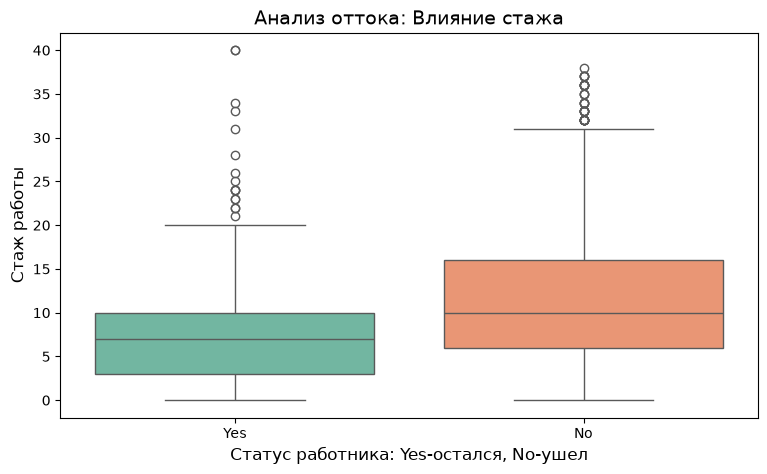

In [4]:
plt.figure(figsize=(9,5))

sns.boxplot(x="Attrition", y="TotalWorkingYears", data=df, palette="Set2", legend=False, hue="Attrition")

plt.title("Анализ оттока: Влияние стажа", fontsize=14)
plt.xlabel("Статус работника: Yes-остался, No-ушел", fontsize=12)
plt.ylabel("Стаж работы", fontsize=12)
plt.show()

Выяснили на графике влияние стажа на решение сотрудника об уходе.

In [5]:
X = pd.get_dummies(df.drop("Attrition", axis=1),
    columns=["BusinessTravel",
    "Department",
    "EducationField",
    "Gender",
    "JobRole",
    "MaritalStatus",
    "Over18",
    "OverTime"], drop_first=True)

y = df["Attrition"]
X.head(3)

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes
0,41,1102,1,2,1,1,2,94,3,2,...,False,False,False,False,False,True,False,False,True,True
1,49,279,8,1,1,2,3,61,2,2,...,False,False,False,False,True,False,False,True,False,False
2,37,1373,2,2,1,4,4,92,2,1,...,True,False,False,False,False,False,False,False,True,True


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

number_cols = ["Age", "TotalWorkingYears", "DistanceFromHome", "Education", "EnvironmentSatisfaction", "HourlyRate", "JobInvolvement", "JobLevel", "JobSatisfaction", "MonthlyIncome", "MonthlyRate", "NumCompaniesWorked", "PercentSalaryHike", "PerformanceRating", "RelationshipSatisfaction", "StandardHours", "StockOptionLevel", "DailyRate", "TrainingTimesLastYear", "WorkLifeBalance", "YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager"]

scaler = StandardScaler()

X_train[number_cols] = scaler.fit_transform(X_train[number_cols])
# только трансформ чтобы модель не поглядывала
X_test[number_cols] = scaler.transform(X_test[number_cols])
X_train.head(3)

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes
1194,1.090194,1.049455,-0.899915,1.064209,1,1676,-0.658710,-0.908436,1.795282,1.762189,...,False,True,False,False,False,False,False,False,False,False
128,-1.634828,-0.523449,-0.899915,-1.855332,1,169,0.260202,1.694111,0.373564,-0.986265,...,True,False,False,False,False,False,False,True,False,False
810,0.981193,-0.992080,-0.777610,-1.855332,1,1124,-1.577622,-0.662913,0.373564,1.762189,...,False,True,False,False,False,False,False,True,False,False


In [7]:
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred) * 100

print(f"Общая точность модели (Accuracy): {accuracy:.2f}%\n")

Общая точность модели (Accuracy): 82.31%



Выяснил точность модели, состовляющую 82,31%